# Model comparison: Faster R-CNN, RetinaNet, FCOS, RT-DETR

All detectors use the same 4,868 training frames, the same 5 video-level folds and the same COCO
evaluation (ignore regions as crowd, maxDets 100). CV = mean over the 5 held-out folds; official validation (OV) = mean of the
5 fold checkpoints, each evaluated once. Every model is shown with the experiment chosen by its CV mAP.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('..').resolve()
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)

## Single checkpoints

In [2]:
def mean_std(text):
    mean, std = text.split(' ± ')
    return float(mean), float(std)

table = pd.read_csv(ROOT / 'model_comparison' / 'comparison_ready_table.csv')
rows = []
for (model, experiment), group in table.groupby(['model', 'experiment'], sort=False):
    cv = group.set_index('evaluation_split').loc['cv_out_of_fold']
    ov = group.set_index('evaluation_split').loc['official_val']
    rows.append(dict(model=model, experiment=experiment, cv_mAP=mean_std(cv['map'])[0], cv_std=mean_std(cv['map'])[1],
                     ov_mAP=mean_std(ov['map'])[0], ov_std=mean_std(ov['map'])[1], ov_AP_small=mean_std(ov['map_small'])[0],
                     ov_AR=mean_std(ov['ar'])[0], ms_per_image=mean_std(ov['ms_per_image'])[0]))

retinanet = pd.read_csv(ROOT / 'retinanet' / 'five_fold_results.csv')
rows.append(dict(model='RetinaNet', experiment='baseline', cv_mAP=retinanet['mAP'].mean(), cv_std=retinanet['mAP'].std(),
                 ov_mAP=retinanet['official_mAP'].mean(), ov_std=retinanet['official_mAP'].std(),
                 ov_AP_small=retinanet['official_APs'].mean(), ov_AR=float('nan'), ms_per_image=float('nan')))

for name, file in [('Faster R-CNN v2', 'v2_lr_scheduler_5fold.csv'), ('Faster R-CNN v2 + scale aug', 'v2_lr_scheduler_scale_aug_5fold.csv')]:
    v2 = pd.read_csv(ROOT / 'faster_rcnn' / 'faster_rcnn_v2' / file)
    rows.append(dict(model=name, experiment='lr_scheduler', cv_mAP=v2['cv_mAP'].mean(), cv_std=v2['cv_mAP'].std(),
                     ov_mAP=v2['official_mAP'].mean(), ov_std=v2['official_mAP'].std()))

single = pd.DataFrame(rows).sort_values('ov_mAP', ascending=False).reset_index(drop=True)
display(single.round(4))

,model,experiment,cv_mAP,cv_std,ov_mAP,ov_std,ov_AP_small,ov_AR,ms_per_image
0,RT-DETR,no_denoising_640x1152,0.2602,0.0302,0.2360,0.0124,0.1138,0.4139,28.4
1,Faster R-CNN v2 + scale aug,lr_scheduler,0.2437,0.0389,0.2219,0.0059,NaN,NaN,NaN
2,Faster R-CNN v2,lr_scheduler,0.2312,0.0376,0.2109,0.0083,NaN,NaN,NaN
3,Faster R-CNN,lr_scheduler,0.2110,0.0337,0.1909,0.0062,0.0879,0.3232,27.2
4,FCOS,F1_ciou,0.1969,0.0314,0.1793,0.0087,0.0858,0.3965,31.6
5,RetinaNet,baseline,0.1787,0.0285,0.1483,0.0048,0.0632,NaN,NaN


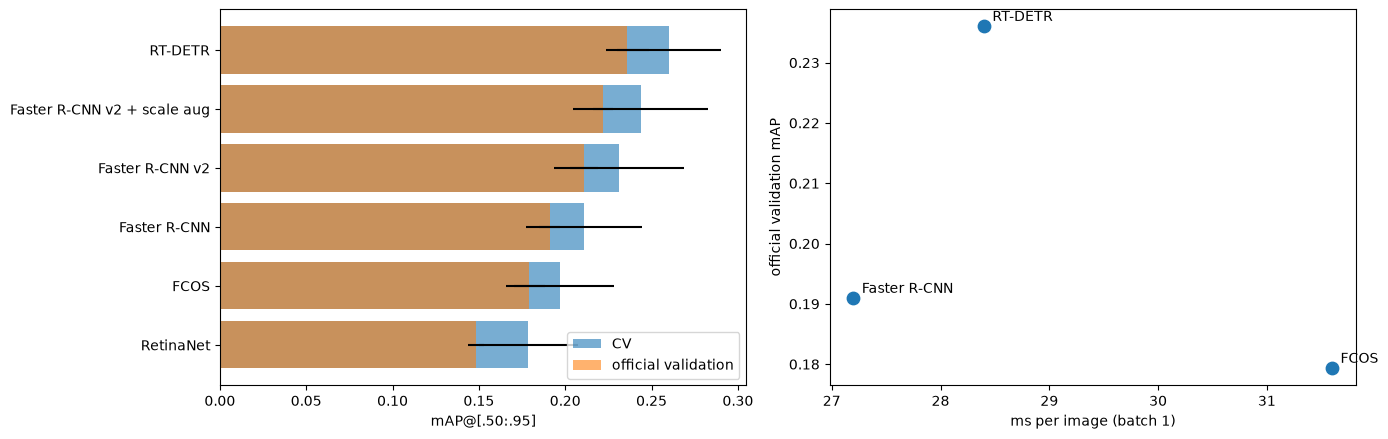

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = single.sort_values('ov_mAP')
axes[0].barh(order['model'], order['cv_mAP'], xerr=order['cv_std'], alpha=0.6, label='CV')
axes[0].barh(order['model'], order['ov_mAP'], xerr=order['ov_std'], alpha=0.6, label='official validation')
axes[0].set_xlabel('mAP@[.50:.95]')
axes[0].legend()
timed = single.dropna(subset=['ms_per_image'])
axes[1].scatter(timed['ms_per_image'], timed['ov_mAP'], s=80)
for _, row in timed.iterrows():
    axes[1].annotate(row['model'], (row['ms_per_image'], row['ov_mAP']), textcoords='offset points', xytext=(6, 4))
axes[1].set_xlabel('ms per image (batch 1)')
axes[1].set_ylabel('official validation mAP')
plt.tight_layout()
plt.show()

## Objects by size

In [4]:
sizes = table[table['evaluation_split'] == 'official_val'].copy()
for column in ['map_small', 'map_medium', 'map_large']:
    sizes[column] = sizes[column].map(lambda text: mean_std(text)[0])
display(sizes[['model', 'experiment', 'map_small', 'map_medium', 'map_large']].round(4))

,model,experiment,map_small,map_medium,map_large
1,Faster R-CNN,lr_scheduler,0.0879,0.1716,0.3612
3,FCOS,F1_ciou,0.0858,0.1584,0.3339
5,RT-DETR,no_denoising_640x1152,0.1138,0.2198,0.4012


## Held-out mAP after every epoch

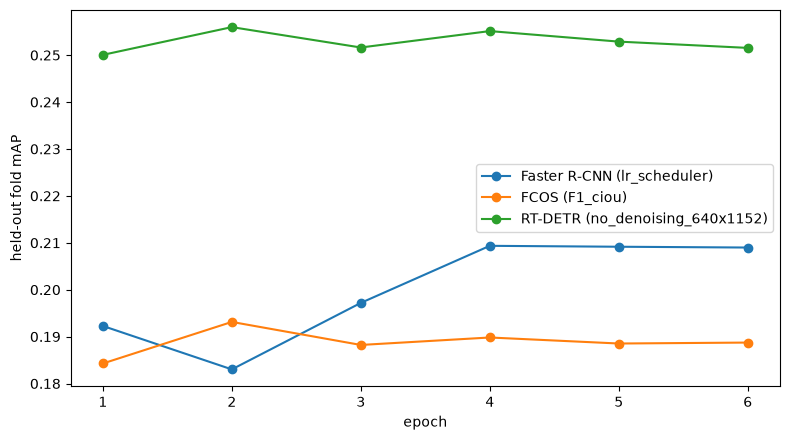

In [5]:
epochs = pd.read_csv(ROOT / 'model_comparison' / 'epoch_metrics.csv')
selected = dict(zip(table['model'], table['experiment']))
fig, ax = plt.subplots(figsize=(8, 4.5))
for model, experiment in selected.items():
    curve = epochs[(epochs['model'] == model) & (epochs['experiment'] == experiment)].groupby('epoch')['map'].mean()
    ax.plot(curve.index, curve.values, marker='o', label=f'{model} ({experiment})')
ax.set_xlabel('epoch')
ax.set_ylabel('held-out fold mAP')
ax.legend()
plt.tight_layout()
plt.show()

## Full pipelines and Kaggle submissions

In [6]:
submissions = pd.read_csv(ROOT / 'kaggle_submissions' / 'submissions.csv', keep_default_na=False)
display(submissions[['pipeline', 'official_val_mAP', 'public_score', 'selected_for_final_score']])

,pipeline,official_val_mAP,public_score,selected_for_final_score
0,"Faster R-CNN lr_scheduler (fold 2 checkpoint), 6 TTA views, WBF",0.2184 (mean of the 5 single checkpoints with the same TTA),0.228957,
1,"Faster R-CNN, 5 fold checkpoints x 6 TTA views, WBF",0.2364,0.258735,
2,"Faster R-CNN, 5 x 6 TTA views, WBF, temporal post-processing",0.2450,0.280954,
3,"Faster R-CNN + FCOS fusion, temporal post-processing",0.2528,0.278987,
4,"B: Faster R-CNN v2 + FCOS fusion, temporal post-processing",0.2928,0.309533,
5,"A: Faster R-CNN v2, 5 x 6 TTA views, WBF, temporal post-processing",0.2841,0.318757,yes
6,"RT-DETR, 5 x 8 TTA views, WBF, temporal post-processing",0.3012,0.320311,yes
